# Determinan dan tiga provinsi

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> Koefisien dari model FGLS determinan, TFP terukur.
--> Sampel koefisien: 34 provinsi, 2017–2024.
--> Tiga provinsi IRS: Sulawesi Tengah, Maluku Utara, Jakarta.


In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from shapely.geometry import Polygon

NAVY, TEAL, GRAY, CREAM, PAPER = (
    "#0E2440", "#46A694", "#797F8C", "#F2E6CE", "#FFFFFF",
)
MUTED = "#A7ADB6"
GRID = "#EEF0F3"
DARK = "#0E2440"
SHORT = {
    11: "Aceh", 12: "Sumut", 13: "Sumbar", 14: "Riau", 15: "Jambi",
    16: "Sumsel", 17: "Bengkulu", 18: "Lampung", 19: "Babel", 21: "Kepri",
    31: "Jakarta", 32: "Jabar", 33: "Jateng", 34: "DIY", 35: "Jatim", 36: "Banten",
    51: "Bali", 52: "NTB", 53: "NTT",
    61: "Kalbar", 62: "Kalteng", 63: "Kalsel", 64: "Kaltim", 65: "Kaltara",
    71: "Sulut", 72: "Sulteng", 73: "Sulsel", 74: "Sultra", 75: "Gorontalo", 76: "Sulbar",
    81: "Maluku", 82: "Malut", 91: "Papua Barat", 94: "Papua",
}
CASES = ["DKI Jakarta", "Sulawesi Tengah", "Maluku Utara"]
COMPARE = ["Kalimantan Timur", "DI Yogyakarta", "Maluku", "Papua Barat"]
IRS = {"DKI Jakarta": "1,54", "Sulawesi Tengah": "2,84", "Maluku Utara": "3,07"}
SECTORS = [
    ("A", "Pertanian", CREAM),
    ("B", "Pertambangan", "#D9042B"),
    ("C", "Industri pengolahan", NAVY),
    ("DEF", "Utilitas dan konstruksi", TEAL),
    ("JASA", "Jasa", "#5DD0E6"),
]
LETTERS = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "MN", "O", "P", "Q", "RSTU"]
DEF = ["D", "E", "F"]
JASA = ["G", "H", "I", "J", "K", "L", "MN", "O", "P", "Q", "RSTU"]

# Model FGLS lengkap. Empat baris partisipasi sudah diarahkan: lebih tinggi = partisipasi lebih besar.
EDU = [
    ("Rata-rata lama sekolah", 0.0839393, 0.0650408, 0.1028378, True),
    ("Harapan lama sekolah", -0.0682066, -0.1046326, -0.0317805, False),
    ("Partisipasi SD", -0.0032614, -0.0138853, 0.0073624, False),
    ("Partisipasi SMP", 0.0118172, -0.0006649, 0.0242993, False),
    ("Partisipasi SMA", -0.0225677, -0.0382183, -0.0069171, False),
    ("Partisipasi pendidikan tinggi", -0.0018315, -0.0316061, 0.0279432, True),
]
EQUITY = [
    ("Tingkat kemiskinan", 0.0229101, 0.0083902, 0.03743, False),
    ("IPM", 0.0102793, -0.01381, 0.0343686, False),
    ("Indeks Gini", -0.0019435, -0.0128619, 0.0089749, False),
    ("Upah rata-rata", -0.0041875, -0.0189997, 0.0106246, False),
    ("Indeks demokrasi", 0.0050818, -0.0034313, 0.0135949, False),
]
FISCAL = [
    ("Tingkat harga", -0.0335061, -0.0444261, -0.0225861, False),
    ("Rasio PAD", 0.1202683, 0.1020999, 0.1384367, False),
    ("Pertumbuhan PDRB", 0.0001639, -0.0063899, 0.0067177, False),
    ("Belanja APBD", 0.3010475, 0.2851949, 0.3169002, False),
]
CONN = [
    ("Jalan mantap", 0.0768162, 0.0621216, 0.0915108, False),
    ("Kargo udara", -0.0192839, -0.0332007, -0.0053671, False),
    ("Kargo kapal", -0.0907258, -0.1244764, -0.0569752, False),
    ("Kargo kereta", 0.1528340, 0.1279728, 0.1776951, False),
    ("Penumpang", -0.0693479, -0.1001019, -0.0385939, False),
    ("Bandara logistik", -0.0001281, -0.0111157, 0.0108594, False),
    ("Bandara komersial", 0.0047920, -0.0063284, 0.0159123, False),
]
ENV = [
    ("Indeks lingkungan", -0.0302310, -0.0458004, -0.0146617, False),
    ("Indeks hijau", -0.0353439, -0.0485269, -0.0221610, False),
    ("Indeks biru", -0.0081128, -0.0164784, 0.0002528, False),
]
SEC = [
    ("Risiko kejahatan", -0.0105001, -0.0175304, -0.0034698, False),
    ("Tingkat kejahatan", -0.0019055, -0.0056850, 0.0018739, False),
]
WAGE = [
    ("Upah primer", 0.0115901, 0.0049150, 0.0182651),
    ("Upah sekunder", 0.0022964, -0.0048877, 0.0094804),
    ("Upah tersier", -0.0080482, -0.0157657, -0.0003307),
]
GROUPS = [
    ("Pendidikan", 0.6303134, 0.5447696, 0.7158573),
    ("Ekuitas", 0.6447687, 0.6294149, 0.6601225),
    ("Institusi", 0.5485636, 0.5352550, 0.5618722),
    ("Konektivitas", 0.4846594, 0.4739469, 0.4953718),
    ("Lingkungan", -0.1666771, -0.1830754, -0.1502788),
    ("Keamanan", -0.0255060, -0.0479851, -0.0030269),
]


def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")


ROOT = find_root()
OUT = ROOT / "01 Data" / "TFP" / "output" / "revisi_53_61"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "axes.unicode_minus": False, "axes.titlecolor": NAVY, "text.color": NAVY,
    "axes.labelcolor": NAVY, "xtick.color": GRAY, "ytick.color": NAVY,
    "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
})


def clean(ax, grid="x"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#E2E5EA")
    ax.spines["bottom"].set_color("#E2E5EA")
    ax.tick_params(length=0)
    if grid:
        ax.set_axisbelow(True)
        ax.grid(True, axis=grid, color=GRID, lw=0.8)


def head(fig, title, subtitle, top=0.88):
    """Store the header; position it after the final subplot layout."""
    fig._report_header = (title, subtitle)
    fig.tight_layout(rect=(0, 0, 1, top))


def _finish_header(fig):
    """Wrap and separate text using rendered sizes, independent of figure height."""
    for artist in getattr(fig, "_report_header_artists", []):
        artist.remove()
    fig._report_header_artists = []
    if not hasattr(fig, "_report_header"):
        return
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    dpi = fig.dpi
    height_px = fig.bbox.height
    width_px = fig.bbox.width * 0.96
    bounds = [ax.get_tightbbox(renderer) for ax in fig.axes if ax.get_visible()]
    bounds += [a.get_window_extent(renderer) for a in fig.legends + fig.texts
               if a.get_visible()]
    content_top = max((b.y1 for b in bounds if b is not None), default=height_px * .9)

    def wrapped(text, size):
        probe = fig.text(0, 0, "", fontsize=size)
        lines = []
        for paragraph in str(text).split("\n"):
            line = ""
            for word in paragraph.split():
                trial = (line + " " + word).strip()
                probe.set_text(trial)
                if line and probe.get_window_extent(renderer).width > width_px:
                    lines.append(line)
                    line = word
                else:
                    line = trial
            lines.append(line)
        probe.remove()
        return "\n".join(lines)

    title, subtitle = fig._report_header
    gap = 10 * dpi / 72
    sub = fig.text(.01, (content_top + gap) / height_px,
                   wrapped(subtitle, 11), ha="left", va="bottom",
                   fontsize=11, color=GRAY, linespacing=1.35)
    fig.canvas.draw()
    sub_box = sub.get_window_extent(fig.canvas.get_renderer())
    main = fig.text(.01, (sub_box.y1 + gap) / height_px,
                    wrapped(title, 16), ha="left", va="bottom",
                    fontsize=16, color=NAVY, fontweight="medium", linespacing=1.25)
    fig._report_header_artists = [main, sub]
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    assert main.get_window_extent(renderer).y0 > sub.get_window_extent(renderer).y1
    assert sub.get_window_extent(renderer).y0 > content_top


def save(fig, name):
    _finish_header(fig)
    fig.savefig(OUT / name, dpi=180, bbox_inches="tight", facecolor=PAPER)
    print(name)
    plt.show()


def crosses(lo, hi):
    return lo < 0 < hi


def draw_blocks(ax, blocks):
    cursor = 0
    ticks, labels, weights = [], [], []
    for title, rows in blocks:
        cursor += 0.55
        ticks.append(cursor)
        labels.append(title)
        weights.append("bold")
        cursor += 0.85
        for lab, b, lo, hi, emph in rows:
            color = MUTED if crosses(lo, hi) else DARK
            ax.plot([lo, hi], [cursor, cursor], color=color, lw=1.7, solid_capstyle="round", zorder=2)
            ax.plot([b], [cursor], "o", ms=7 if emph else 5.5, color=color, zorder=3)
            ticks.append(cursor)
            labels.append(lab)
            weights.append("bold" if emph else "regular")
            cursor += 0.85
        cursor += 0.35
    ax.axvline(0, color="#C8CDD4", lw=1.0, zorder=1)
    ax.set_yticks(ticks)
    ax.set_yticklabels(labels, fontsize=10)
    for tick, weight in zip(ax.get_yticklabels(), weights):
        tick.set_fontweight(weight)
        tick.set_color(DARK if weight == "bold" else NAVY)
    ax.set_ylim(cursor - 0.2, -0.35)
    clean(ax, grid="x")
    return cursor


## Teks utama


### Gambar 8. Koefisien FGLS


08_koefisien_fgls.png


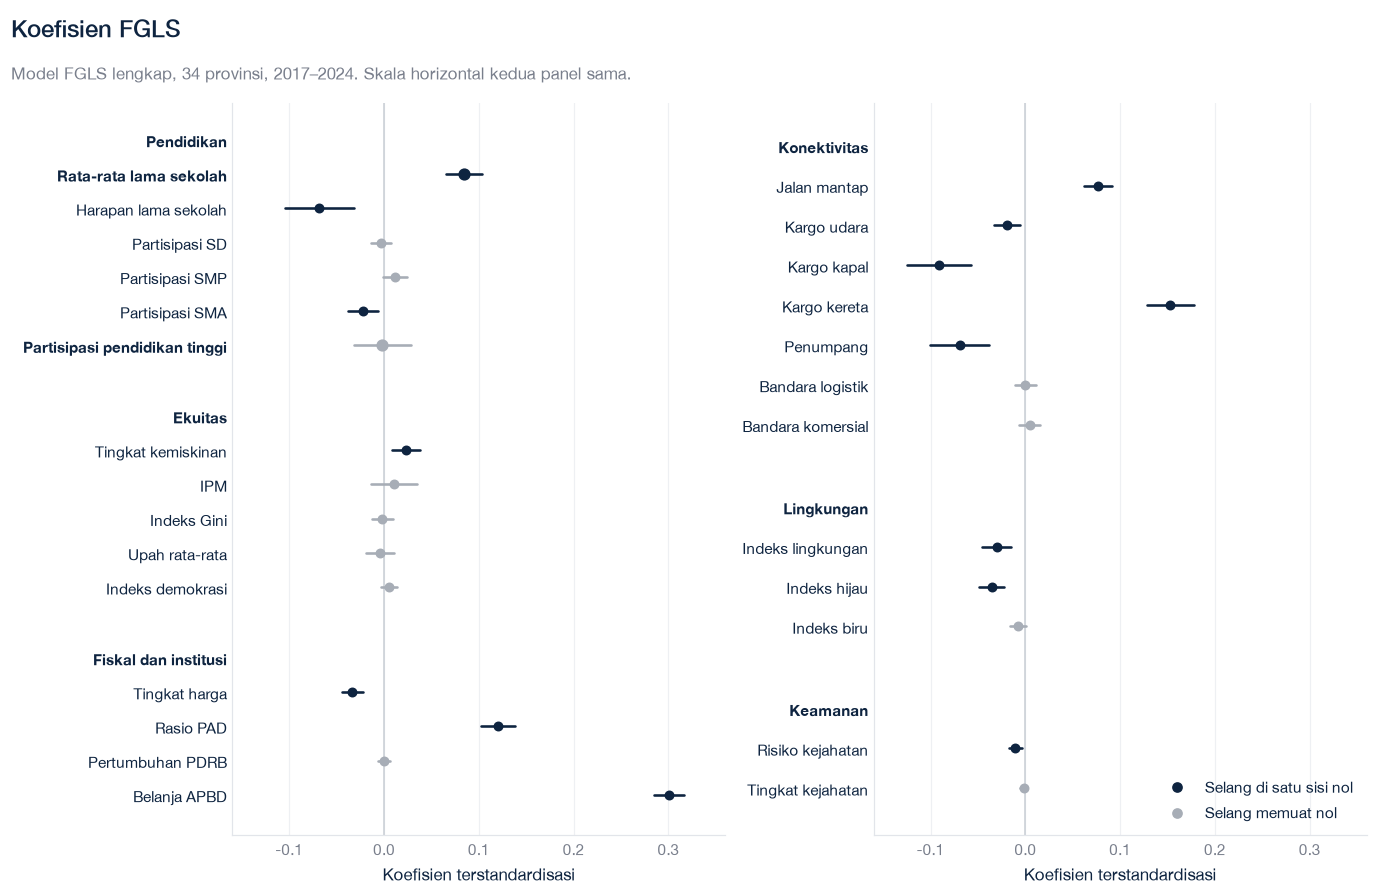

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 8.6), sharex=True)
draw_blocks(axes[0], [("Pendidikan", EDU), ("Ekuitas", EQUITY), ("Fiskal dan institusi", FISCAL)])
draw_blocks(axes[1], [("Konektivitas", CONN), ("Lingkungan", ENV), ("Keamanan", SEC)])
for ax in axes:
    ax.set_xlim(-0.16, 0.36)
    ax.set_xlabel("Koefisien terstandardisasi")
axes[1].plot([], [], "o", color=DARK, ms=6, label="Selang di satu sisi nol")
axes[1].plot([], [], "o", color=MUTED, ms=6, label="Selang memuat nol")
axes[1].legend(frameon=False, fontsize=10, loc="lower right")
head(fig, "Koefisien FGLS",
     "Model FGLS lengkap, 34 provinsi, 2017–2024. Skala horizontal kedua panel sama.", top=0.86)
save(fig, "08_koefisien_fgls.png")


--> Garis menunjukkan interval kepercayaan 95%.
--> Titik menunjukkan estimasi.
--> Warna gelap: selang 95 persen di satu sisi nol. Abu-abu: selang memuat nol.
--> Nama indikator yang ditebalkan pada kelompok pendidikan adalah rata-rata lama sekolah dan partisipasi pendidikan tinggi.
--> Empat indikator partisipasi diarahkan sehingga nilai lebih tinggi berarti partisipasi lebih besar.
--> Indeks Gini yang lebih tinggi berarti ketimpangan yang lebih tinggi.
--> Belanja APBD dan rasio PAD adalah kondisi fiskal pada model yang sama.


### Gambar 9. Enam indikator pendidikan


09_pendidikan_fgls.png


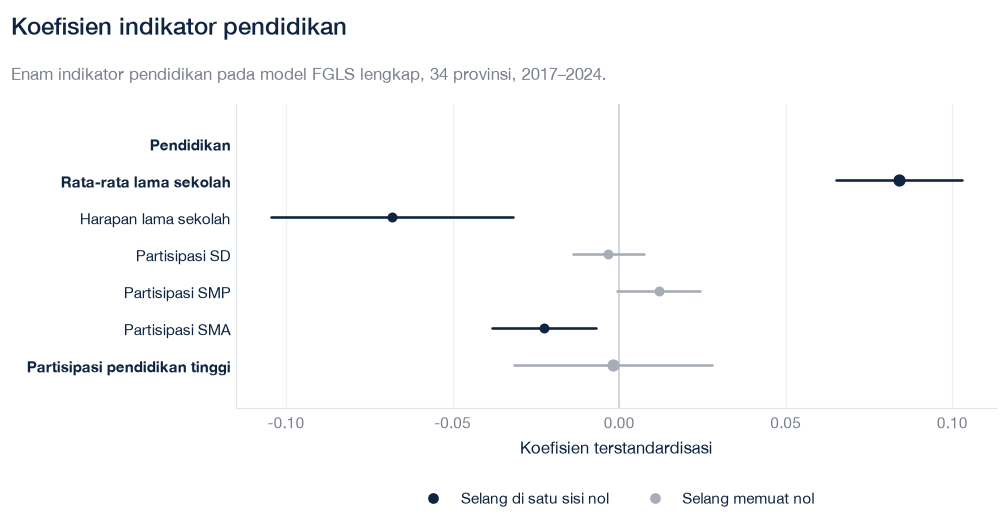

In [3]:
fig, ax = plt.subplots(figsize=(9.2, 4.8))
draw_blocks(ax, [("Pendidikan", EDU)])
ax.set_xlabel("Koefisien terstandardisasi")
ax.plot([], [], "o", color=DARK, ms=6, label="Selang di satu sisi nol")
ax.plot([], [], "o", color=MUTED, ms=6, label="Selang memuat nol")
ax.legend(frameon=False, fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
head(fig, "Koefisien indikator pendidikan",
     "Enam indikator pendidikan pada model FGLS lengkap, 34 provinsi, 2017–2024.")
save(fig, "09_pendidikan_fgls.png")


--> Titik adalah estimasi; garis adalah interval kepercayaan 95%.
--> Partisipasi diarahkan sehingga nilai lebih tinggi berarti partisipasi lebih besar.


### Gambar 10. Upah sektoral


10_upah_sektoral.png


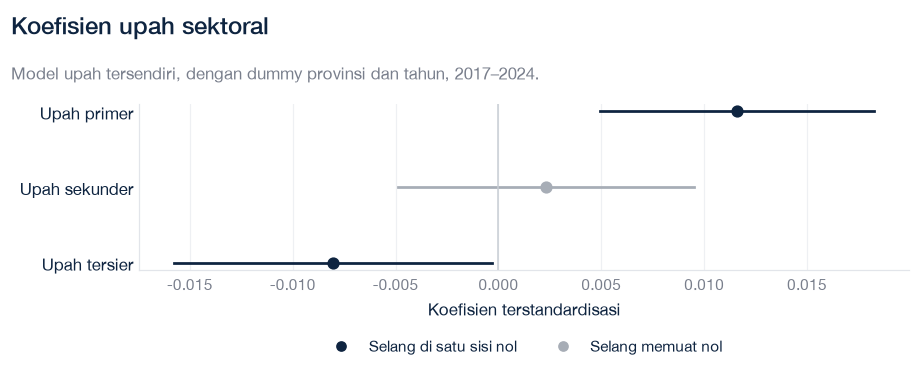

In [4]:
fig, ax = plt.subplots(figsize=(8.4, 3.4))
for i, (lab, b, lo, hi) in enumerate(WAGE):
    color = MUTED if crosses(lo, hi) else DARK
    ax.plot([lo, hi], [i, i], color=color, lw=1.8, zorder=2)
    ax.plot([b], [i], "o", color=color, ms=7, zorder=3)
ax.axvline(0, color="#C8CDD4", lw=1)
ax.set_yticks(range(3))
ax.set_yticklabels([w[0] for w in WAGE], fontsize=11)
ax.invert_yaxis()
ax.set_xlabel("Koefisien terstandardisasi")
ax.plot([], [], "o", color=DARK, ms=6, label="Selang di satu sisi nol")
ax.plot([], [], "o", color=MUTED, ms=6, label="Selang memuat nol")
ax.legend(frameon=False, fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
clean(ax, grid="x")
head(fig, "Koefisien upah sektoral",
     "Model upah tersendiri, dengan dummy provinsi dan tahun, 2017–2024.")
save(fig, "10_upah_sektoral.png")


--> Model upah tersendiri, dummy provinsi dan tahun, 2017–2024.
--> Titik adalah estimasi; garis adalah interval kepercayaan 95%.
--> Warna gelap: selang 95 persen di satu sisi nol.


### Gambar 11. Tiga provinsi


03_viz_pendidikan.ipynb:1:129: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
11_kasus_irs.png


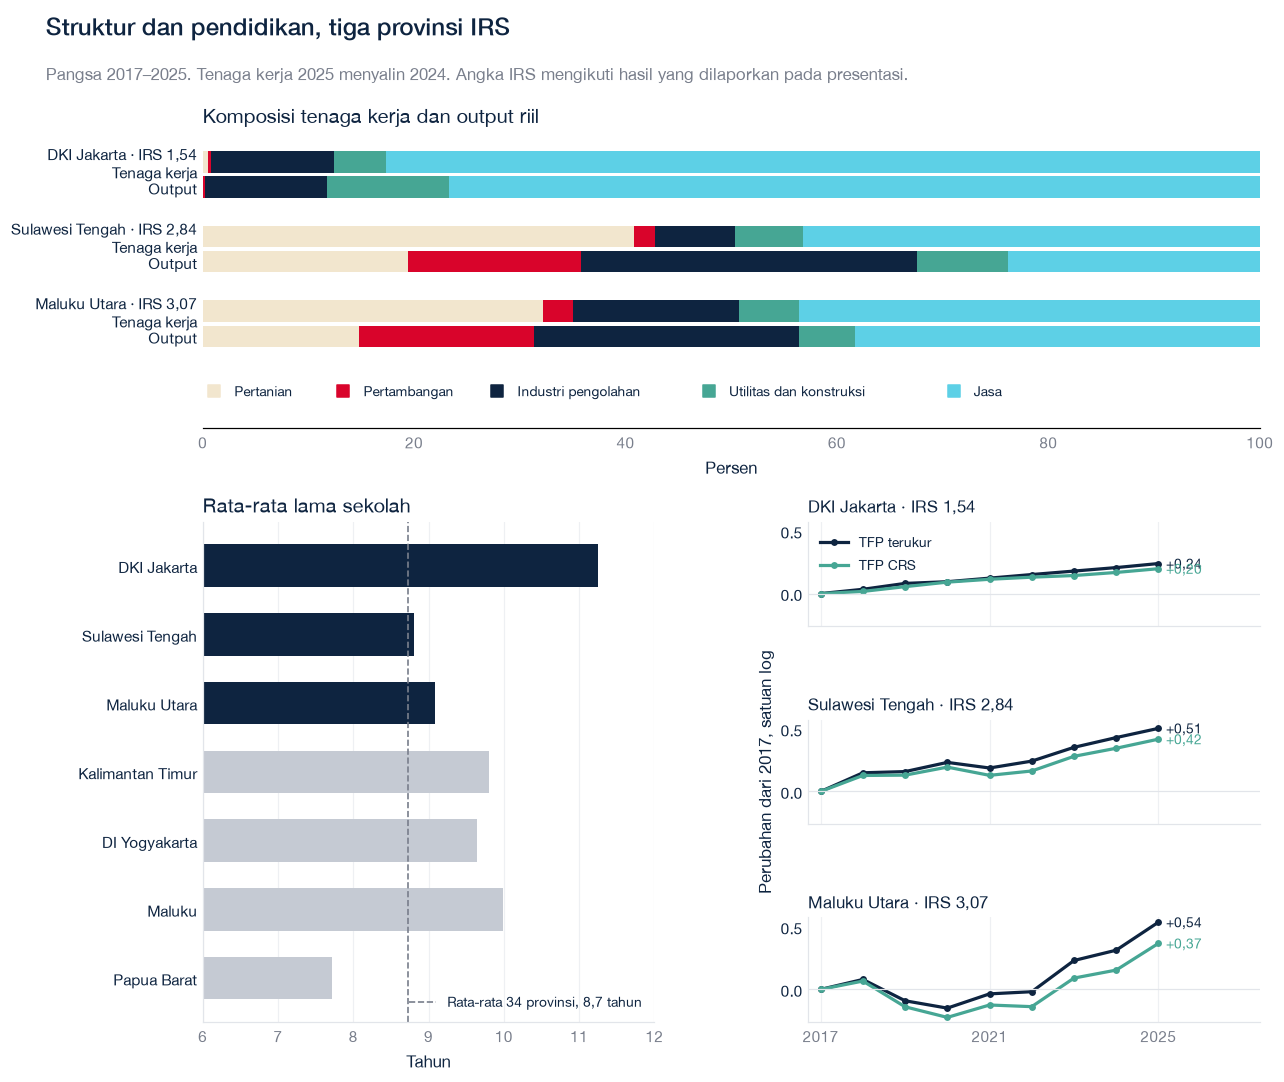

In [5]:
tfp = pd.read_excel(ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx", sheet_name="tfp")
tfp["Pre_Prov"] = tfp.Pre_Prov.replace({"DI yogyakarta": "DI Yogyakarta"})
tfp["short"] = tfp.Code_Prov.map(SHORT)
ev = pd.read_excel(ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx", sheet_name="kovariat")
ev = ev.loc[ev.Year.between(2017, 2025)].copy()
ev["Pre_Prov"] = ev.Pre_Prov.replace({"DI yogyakarta": "DI Yogyakarta"})
school = ev.groupby(["Code_Prov", "Pre_Prov"], as_index=False).lama_sekolah_mean.mean()
bench = school.lama_sekolah_mean.mean()

src = pd.read_excel(
    ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx",
    sheet_name="sektor",
)
src = src.loc[src.Year.between(2017, 2025)].copy()
src["Pre_Prov"] = src.Pre_Prov.replace({"DI yogyakarta": "DI Yogyakarta"})
tk = {s: f"{s}_TenagaKerja" for s in LETTERS}
yk = {s: f"{s}_ADHK" for s in LETTERS}
lvl = src.groupby(["Code_Prov", "Pre_Prov"], as_index=False)[list(tk.values()) + list(yk.values())].mean()


def pack(frame, cols):
    out = pd.DataFrame({
        "A": frame[cols["A"]],
        "B": frame[cols["B"]],
        "C": frame[cols["C"]],
        "DEF": frame[[cols[s] for s in DEF]].sum(axis=1),
        "JASA": frame[[cols[s] for s in JASA]].sum(axis=1),
    })
    return out.div(out.sum(axis=1), axis=0)


comp = pd.concat([
    lvl[["Code_Prov", "Pre_Prov"]],
    pack(lvl, tk).add_prefix("tk_"),
    pack(lvl, yk).add_prefix("y_"),
], axis=1)
focus = comp.loc[comp.Pre_Prov.isin(CASES)].copy()
focus["ord"] = focus.Pre_Prov.map({n: i for i, n in enumerate(CASES)})
focus = focus.sort_values("ord")

fig = plt.figure(figsize=(12.4, 10.4))
gs = fig.add_gridspec(4, 2, height_ratios=[1.7, 0.62, 0.62, 0.62], hspace=0.62, wspace=0.34)
ax_s = fig.add_subplot(gs[0, :])
ypos, ylabels = [], []
for i, r in enumerate(focus.itertuples(index=False)):
    base_y = i * 2.5
    for shift, prefix, tag in [(0.0, "tk_", "Tenaga kerja"), (0.85, "y_", "Output")]:
        left = 0
        y = base_y + shift
        for key, lab, color in SECTORS:
            val = 100 * getattr(r, f"{prefix}{key}")
            ax_s.barh(y, val, left=left, height=0.72, color=color)
            left += val
        ypos.append(y)
        if prefix == "tk_":
            ylabels.append(f"{r.Pre_Prov} · IRS {IRS[r.Pre_Prov]}\nTenaga kerja")
        else:
            ylabels.append("Output")
ax_s.set_yticks(ypos)
ax_s.set_yticklabels(ylabels, fontsize=10)
ax_s.set_xlim(0, 100)
ax_s.set_xlabel("Persen")
ax_s.invert_yaxis()
bottom, top = ax_s.get_ylim()
ax_s.set_ylim(bottom + 2.4, top)
y_leg = bottom + 1.15
x_leg = 0.0
for _key, lab, color in SECTORS:
    ax_s.scatter([x_leg + 1.1], [y_leg], s=64, marker="s", color=color, clip_on=False, zorder=4)
    ax_s.text(x_leg + 3.0, y_leg, lab, va="center", ha="left", fontsize=9, color=NAVY)
    x_leg += 3.0 + len(lab) * 0.78 + 2.2
ax_s.set_title("Komposisi tenaga kerja dan output riil", loc="left", fontsize=13, pad=12)
ax_s.spines["top"].set_visible(False)
ax_s.spines["right"].set_visible(False)
ax_s.spines["left"].set_visible(False)
ax_s.tick_params(length=0)

ax_e = fig.add_subplot(gs[1:, 0])
edu_names = CASES + COMPARE
edu = school.loc[school.Pre_Prov.isin(edu_names)].copy()
edu["ord"] = edu.Pre_Prov.map({n: i for i, n in enumerate(edu_names)})
edu = edu.sort_values("ord", ascending=False)
colors = [NAVY if n in CASES else "#C5CAD3" for n in edu.Pre_Prov]
ax_e.barh(edu.Pre_Prov, edu.lama_sekolah_mean, color=colors, height=0.62)
ax_e.axvline(bench, color=GRAY, lw=1.1, ls="--")
bench_label = f"Rata-rata 34 provinsi, {bench:.1f} tahun".replace(".", ",")
ax_e.set_xlim(6, 12)
ax_e.set_xlabel("Tahun")
ax_e.set_title("Rata-rata lama sekolah", loc="left", fontsize=13)
ax_e.plot([], [], color=GRAY, ls="--", lw=1.1, label=bench_label)
ax_e.legend(frameon=False, fontsize=9, loc="lower right")
clean(ax_e, grid="x")

axes_t = []
for i, name in enumerate(CASES):
    ax = fig.add_subplot(gs[i + 1, 1], sharey=axes_t[0] if axes_t else None)
    axes_t.append(ax)
    sub = tfp.loc[tfp.Pre_Prov == name].sort_values("Year")
    for col, color, lab in [
        ("logtfp_it", NAVY, "TFP terukur"),
        ("logtfp_it_crs", TEAL, "TFP CRS"),
    ]:
        base = sub.loc[sub.Year == 2017, col].iloc[0]
        path = sub[col] - base
        ax.plot(sub.Year, path, color=color, lw=2.1, marker="o", ms=3.5, label=lab if i == 0 else None)
        end = path.iloc[-1]
        ax.text(2025.18, end, f"{end:+.2f}".replace(".", ","), color=color, fontsize=9, va="center")
    ax.axhline(0, color="#E2E5EA", lw=0.8)
    ax.set_xlim(2016.7, 2027.4)
    ax.set_xticks([2017, 2021, 2025])
    ax.set_title(f"{name} · IRS {IRS[name]}", loc="left", fontsize=11)
    clean(ax)
    if i < 2:
        ax.tick_params(labelbottom=False)
axes_t[1].set_ylabel("Perubahan dari 2017, satuan log")
axes_t[0].legend(frameon=False, fontsize=9, loc="upper left")
head(fig, "Struktur dan pendidikan, tiga provinsi IRS",
     "Pangsa 2017–2025. Tenaga kerja 2025 menyalin 2024. Angka IRS mengikuti hasil yang dilaporkan pada presentasi.", top=0.90)
save(fig, "11_kasus_irs.png")


--> Garis putus-putus adalah rata-rata tak tertimbang 34 provinsi.
--> Angka di ujung garis TFP adalah perubahan residual CRS dari 2017 ke 2025.
--> Tenaga kerja 2025 menyalin 2024, dan koefisien produksi tidak diestimasi ulang.
--> Batang biru pada lama sekolah adalah tiga provinsi IRS.


### Gambar 12. Kontribusi terhadap pertumbuhan agregat


12_kontribusi_pertumbuhan.png


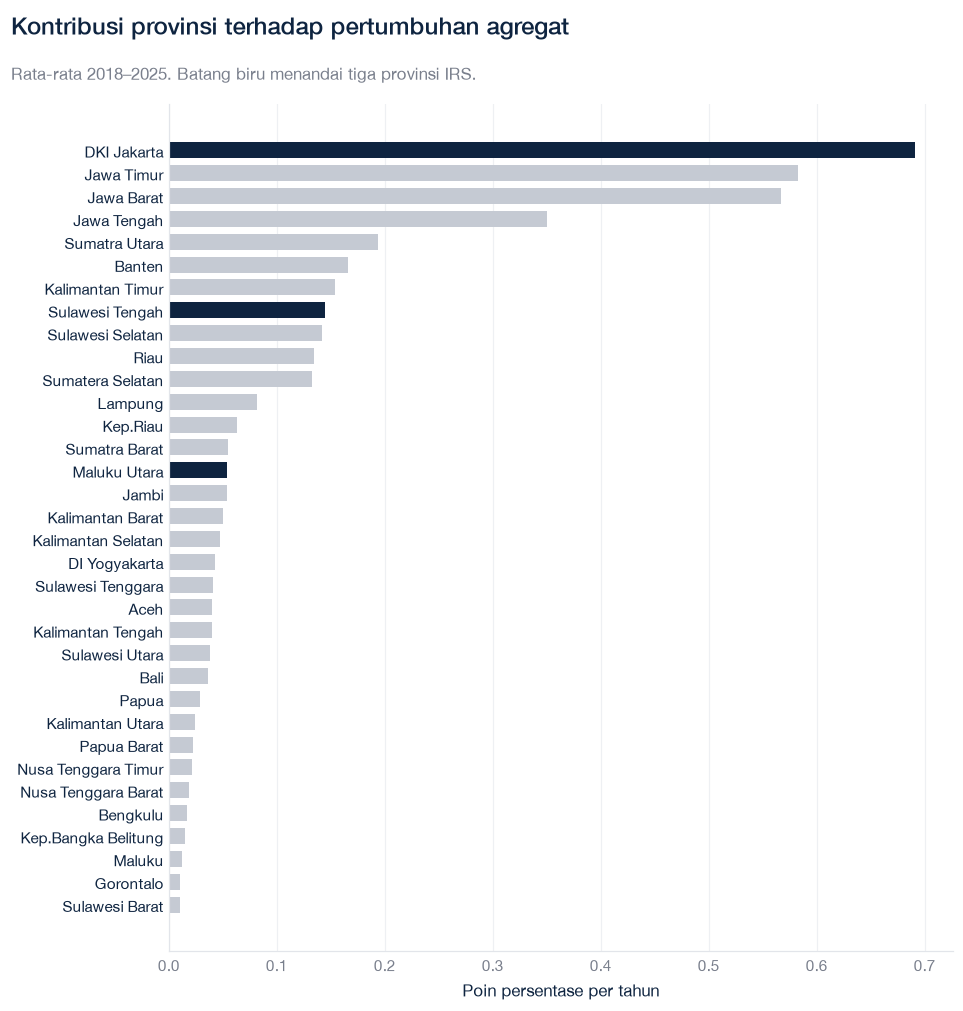

In [6]:
wide = tfp.pivot(index="Year", columns="Code_Prov", values="pdrb_adhk").sort_index()
pieces = []
for year in range(2018, 2026):
    y0, y1 = wide.loc[year - 1], wide.loc[year]
    pieces.append(100 * (y0 / y0.sum()) * (y1 / y0 - 1))
kontrib = pd.concat(pieces, axis=1).mean(axis=1).rename("kontrib").reset_index()
kontrib = kontrib.merge(tfp[["Code_Prov", "Pre_Prov"]].drop_duplicates(), on="Code_Prov")
kontrib = kontrib.sort_values("kontrib")
fig, ax = plt.subplots(figsize=(8.8, 9.6))
colors = [NAVY if n in CASES else "#C5CAD3" for n in kontrib.Pre_Prov]
ax.barh(kontrib.Pre_Prov, kontrib.kontrib, color=colors, height=0.7)
ax.set_xlabel("Poin persentase per tahun")
clean(ax, grid="x")
head(fig, "Kontribusi provinsi terhadap pertumbuhan agregat",
     "Rata-rata 2018–2025. Batang biru menandai tiga provinsi IRS.")
save(fig, "12_kontribusi_pertumbuhan.png")


--> Angka pada gambar adalah rata-rata 2018–2025.
--> Jumlah seluruh provinsi sama dengan pertumbuhan jumlah 34 provinsi.
--> Kontribusi suatu provinsi pada satu tahun adalah bobot output tahun sebelumnya dikali pertumbuhan outputnya.


## Lampiran


A8_jumlah_tema.png
A9_dashboard_kasus.png
A10_profil_pilar.png
A11_peta_kondisi.png
A12_sebaran_sekolah.png


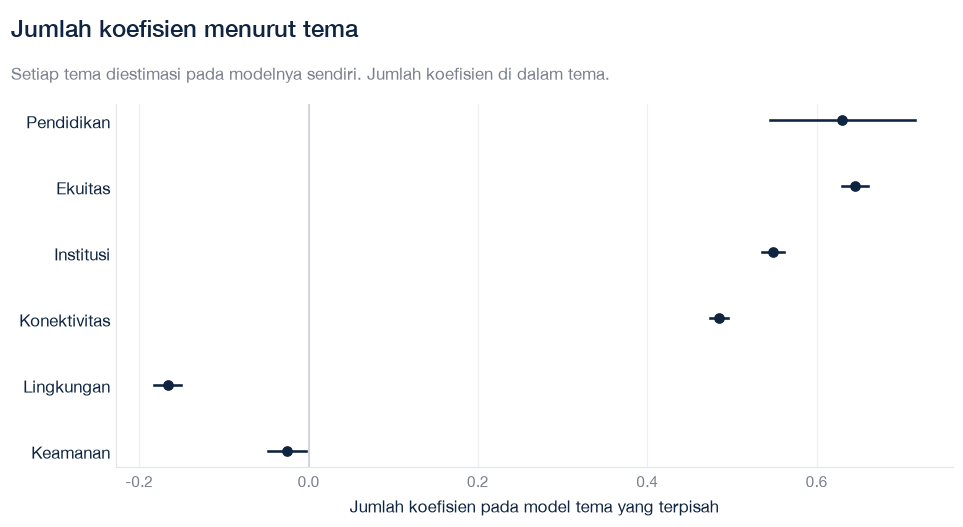

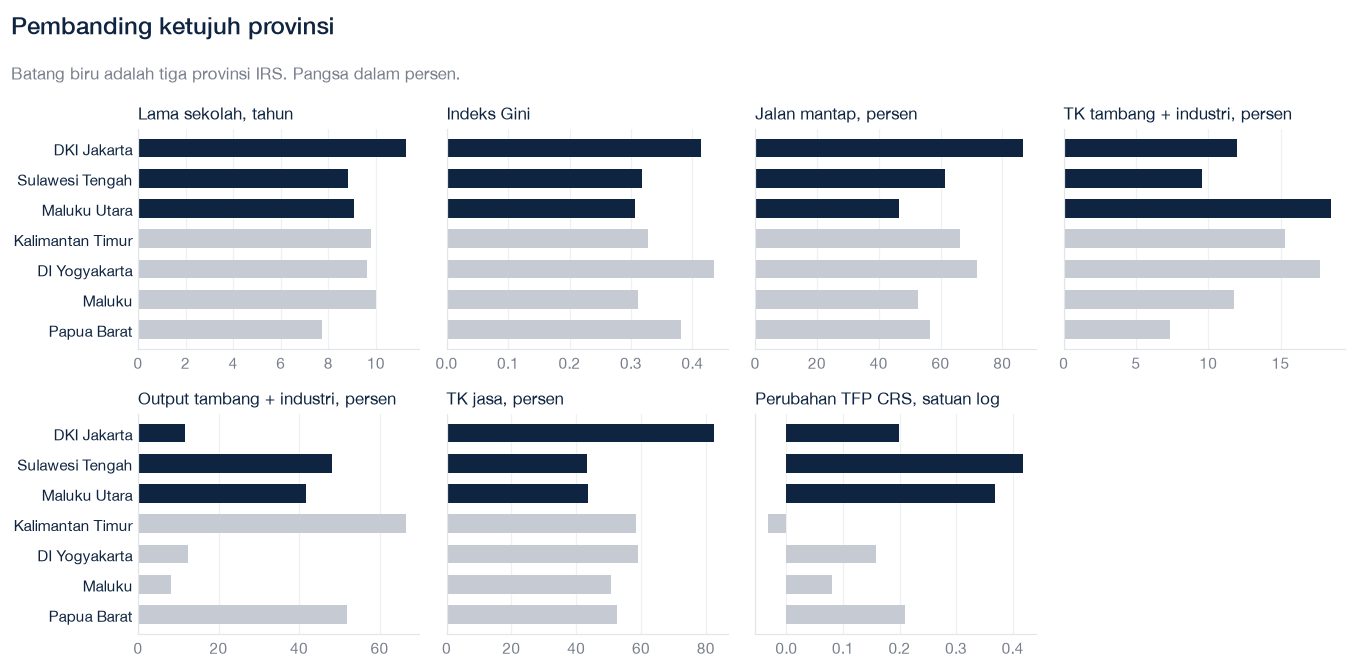

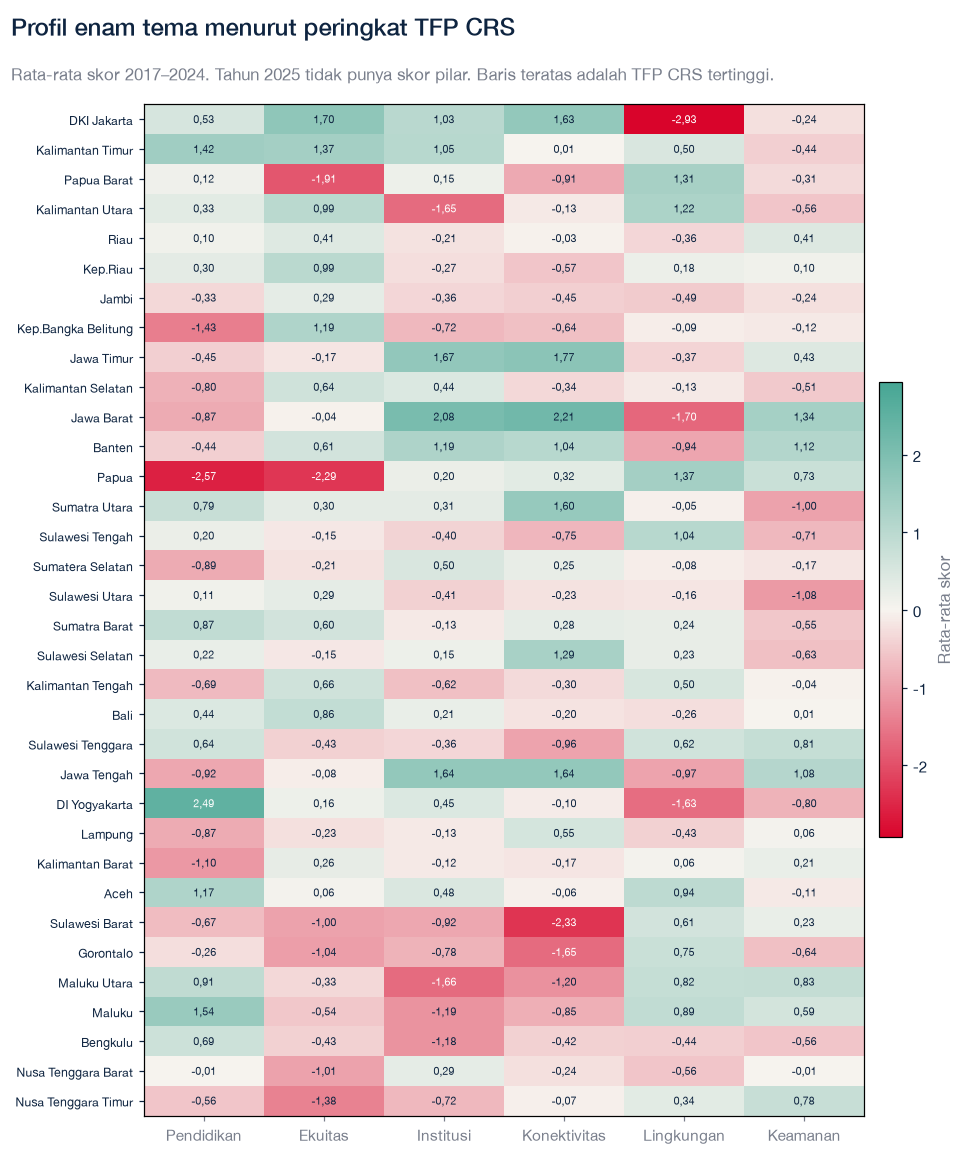

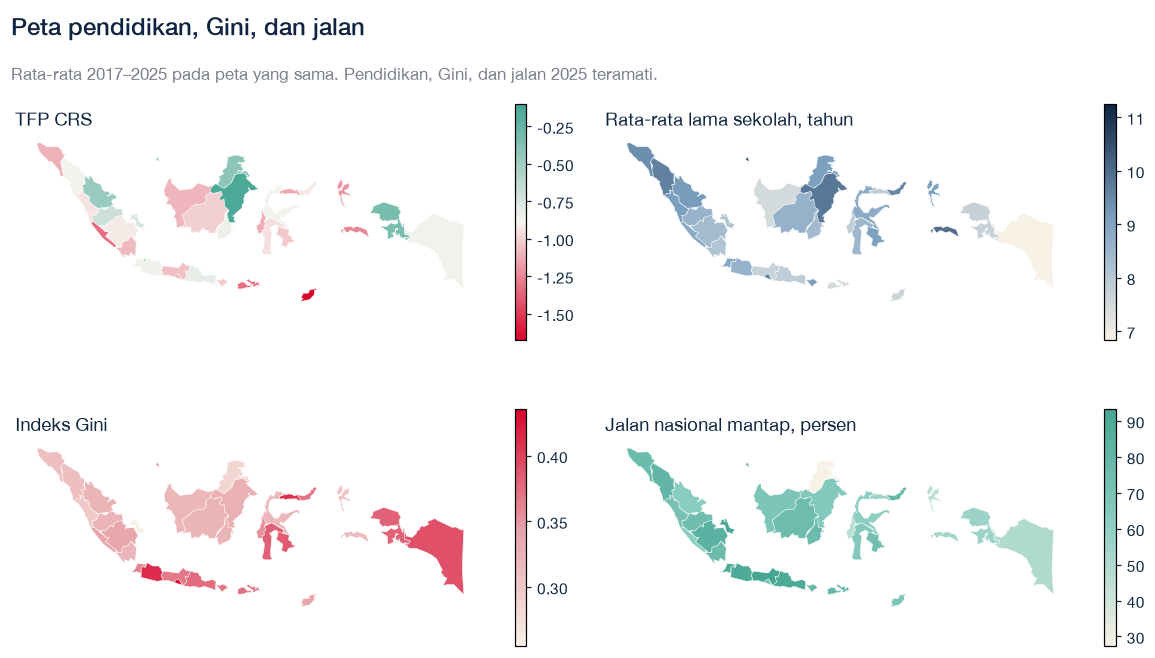

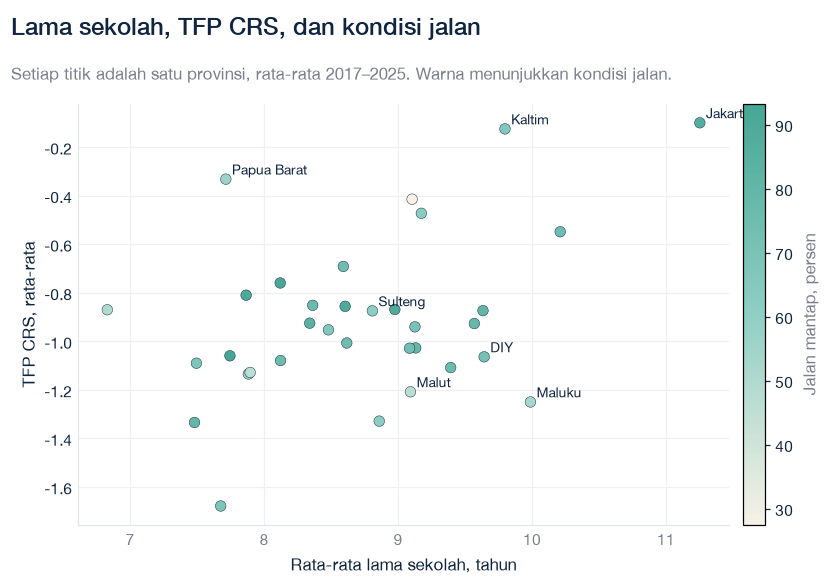

In [7]:
fig, ax = plt.subplots(figsize=(8.8, 4.6))
rows = list(reversed(GROUPS))
for i, (lab, b, lo, hi) in enumerate(rows):
    color = MUTED if crosses(lo, hi) else DARK
    ax.plot([lo, hi], [i, i], color=color, lw=1.7)
    ax.plot([b], [i], "o", color=color, ms=6)
ax.axvline(0, color="#C8CDD4", lw=1)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([r[0] for r in rows], fontsize=11)
ax.set_xlabel("Jumlah koefisien pada model tema yang terpisah")
clean(ax, grid="x")
head(fig, "Jumlah koefisien menurut tema",
     "Setiap tema diestimasi pada modelnya sendiri. Jumlah koefisien di dalam tema.")
save(fig, "A8_jumlah_tema.png")

# supporting dashboard, percentages, with manufacturing output and services
chg = tfp.pivot(index="Pre_Prov", columns="Year", values="logtfp_it_crs")
panel = school.merge(comp, on=["Code_Prov", "Pre_Prov"])
panel["d_c"] = panel.Pre_Prov.map(lambda n: chg.loc[n, 2025] - chg.loc[n, 2017])
gini = ev.groupby("Pre_Prov").gini.mean()
road = ev.groupby("Pre_Prov").jalan_mantap_pc.mean()
panel["gini"] = panel.Pre_Prov.map(gini)
panel["road"] = panel.Pre_Prov.map(road)
panel["tk_bc"] = 100 * (panel.tk_B + panel.tk_C)
panel["y_bc"] = 100 * (panel.y_B + panel.y_C)
panel["tk_jasa"] = 100 * panel.tk_JASA
show_names = CASES + COMPARE
show = panel.loc[panel.Pre_Prov.isin(show_names)].copy()
show["ord"] = show.Pre_Prov.map({n: i for i, n in enumerate(show_names)})
show = show.sort_values("ord", ascending=False)
metrics = [
    ("lama_sekolah_mean", "Lama sekolah, tahun", None),
    ("gini", "Indeks Gini", None),
    ("road", "Jalan mantap, persen", None),
    ("tk_bc", "TK tambang + industri, persen", None),
    ("y_bc", "Output tambang + industri, persen", None),
    ("tk_jasa", "TK jasa, persen", None),
    ("d_c", "Perubahan TFP CRS, satuan log", None),
]
fig, axes = plt.subplots(2, 4, figsize=(12.4, 6.2))
axes = list(axes.ravel())
for i, (ax, (col, title, _)) in enumerate(zip(axes, metrics)):
    colors = [NAVY if n in CASES else "#C5CAD3" for n in show.Pre_Prov]
    ax.barh(show.Pre_Prov, show[col], color=colors, height=0.62)
    ax.set_title(title, loc="left", fontsize=11)
    clean(ax, grid="x")
    if i % 4:
        ax.tick_params(labelleft=False)
axes[-1].axis("off")
head(fig, "Pembanding ketujuh provinsi",
     "Batang biru adalah tiga provinsi IRS. Pangsa dalam persen.", top=0.86)
save(fig, "A9_dashboard_kasus.png")

# profile heatmap
rank = tfp.groupby("Code_Prov").logtfp_it_crs.mean().rank(ascending=False, method="min")
pillars = ["pilar_pendidikan", "pilar_equity", "pilar_institusi", "pilar_konektivitas", "pilar_lingkungan", "pilar_keamanan"]
prof = ev.groupby(["Code_Prov", "Pre_Prov"], as_index=False)[pillars].mean()
prof["r"] = prof.Code_Prov.map(rank)
prof = prof.sort_values("r")
mat = prof[pillars].to_numpy()
lim = np.nanmax(np.abs(mat))
cmap = LinearSegmentedColormap.from_list("div", ["#D9042B", "#F7F4EF", TEAL])
fig, ax = plt.subplots(figsize=(8.8, 10.6))
im = ax.imshow(mat, cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(6))
ax.set_xticklabels(["Pendidikan", "Ekuitas", "Institusi", "Konektivitas", "Lingkungan", "Keamanan"], fontsize=10)
ax.set_yticks(range(len(prof)))
ax.set_yticklabels(prof.Pre_Prov, fontsize=8)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        val = mat[i, j]
        t = (val + lim) / (2 * lim)
        r, g, b, _ = cmap(t)
        lum = 0.299 * r + 0.587 * g + 0.114 * b
        ax.text(j, i, f"{val:.2f}".replace(".", ","), ha="center", va="center", fontsize=7,
                color="white" if lum < 0.62 else NAVY)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02).set_label("Rata-rata skor", color=GRAY)
head(fig, "Profil enam tema menurut peringkat TFP CRS",
     "Rata-rata skor 2017–2024. Tahun 2025 tidak punya skor pilar. Baris teratas adalah TFP CRS tertinggi.", top=0.92)
save(fig, "A10_profil_pilar.png")

base = ev.groupby(["Code_Prov", "Pre_Prov"], as_index=False)[
    ["lama_sekolah_mean", "gini", "jalan_mantap_pc"]
].mean()
crs = tfp.groupby("Code_Prov").logtfp_it_crs.mean().rename("tfp_crs")
base = base.merge(crs, left_on="Code_Prov", right_index=True)
raw = json.loads((ROOT / "01 Data/TFP/output/luaran 2/maps/canvas_polygons.json").read_text())
geoms = []
for rec in raw:
    nums = list(map(float, re.findall(r"[-+]?\d*\.?\d+", rec["d"])))
    coords = list(zip(nums[0::2], [-v for v in nums[1::2]]))
    geoms.append({"Code_Prov": int(rec["c"]), "geometry": Polygon(coords)})
maps = gpd.GeoDataFrame(geoms, geometry="geometry").merge(base, on="Code_Prov")
seq = LinearSegmentedColormap.from_list("seq", ["#F7F1E6", "#7FA3C4", NAVY])
road = LinearSegmentedColormap.from_list("road", ["#F7F1E6", "#8FCFC4", TEAL])
ginimap = LinearSegmentedColormap.from_list("gini", ["#F7F1E6", "#E7A0A8", "#D9042B"])
div = LinearSegmentedColormap.from_list("div", ["#D9042B", "#F7F4EF", TEAL])
fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.4))
specs = [
    (axes[0, 0], "tfp_crs", div, "TFP CRS"),
    (axes[0, 1], "lama_sekolah_mean", seq, "Rata-rata lama sekolah, tahun"),
    (axes[1, 0], "gini", ginimap, "Indeks Gini"),
    (axes[1, 1], "jalan_mantap_pc", road, "Jalan nasional mantap, persen"),
]
for ax, col, cm, title in specs:
    maps.plot(column=col, cmap=cm, ax=ax, edgecolor="white", linewidth=0.3, legend=True,
              legend_kwds={"shrink": 0.6})
    ax.set_axis_off()
    ax.set_title(title, loc="left", fontsize=12)
head(fig, "Peta pendidikan, Gini, dan jalan",
     "Rata-rata 2017–2025 pada peta yang sama. Pendidikan, Gini, dan jalan 2025 teramati.", top=0.90)
save(fig, "A11_peta_kondisi.png")

fig, ax = plt.subplots(figsize=(7.6, 5.2))
sc = ax.scatter(base.lama_sekolah_mean, base.tfp_crs, c=base.jalan_mantap_pc, cmap=road,
                s=48, edgecolor=NAVY, linewidth=0.3, zorder=3)
for _, r in base.iterrows():
    if r.Pre_Prov in CASES + COMPARE:
        ax.annotate(SHORT[r.Code_Prov], (r.lama_sekolah_mean, r.tfp_crs),
                    textcoords="offset points", xytext=(4, 3), fontsize=9)
ax.set_xlabel("Rata-rata lama sekolah, tahun")
ax.set_ylabel("TFP CRS, rata-rata")
clean(ax, grid="both")
fig.colorbar(sc, ax=ax, fraction=0.05, pad=0.02).set_label("Jalan mantap, persen", color=GRAY)
head(fig, "Lama sekolah, TFP CRS, dan kondisi jalan",
     "Setiap titik adalah satu provinsi, rata-rata 2017–2025. Warna menunjukkan kondisi jalan.")
save(fig, "A12_sebaran_sekolah.png")


--> Lampiran menyimpan jumlah koefisien per tema, pembanding tujuh provinsi, profil skor, peta, dan sebaran antarprovinsi.
